# LPS Geometry / Clipping Manufacturing Investigation

## Storytelling — the manufacturing problem

This project investigates whether dimensional variation in an injection-moulded component (by cavity) is associated with clipping performance (failure in leakage test).

Central hypothesis:

**Machine / cavity conditions → geometry and gap variation → clipping risk**

The analysis follows:

**Problem → Data → Evidence → Hypothesis → Statistical test → Engineering interpretation → Action**

### Main questions
1. Are there machine-to-machine geometry differences?
2. Are specific cavities more problematic?
3. Where are clipping failures concentrated?
4. Do OK and FAIL observations have different geometry distributions?
5. Is clipping gap associated with geometry?
6. What additional evidence is needed before naming the root cause?

This project is independent from the Particles/IRR case and reads only `lps_geometry.csv`.

## 1. Architecture

`lps_geometry.csv → bronze_lps_geometry → silver_lps_geometry → gold analytical tables → Python statistics → SQLite → Streamlit`

No derivative CSVs are required.

Instead of using the CSV files, the data is structured in a data base, following the medallion architecture.

In [10]:
from pathlib import Path
import sqlite3
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
DATA_PATH = Path("lps_geometry.csv")
DB_PATH = Path("lps_geometry_clipping_analysis.db")
APP_PATH = Path("lps_clipping_investigation_dashboard.py")
ALPHA = 0.05

## 2. Read and understand the raw data

In [3]:
raw = pd.read_csv(DATA_PATH)
print("Shape:", raw.shape)
display(raw.head())
display(raw.describe(include="all").T)

display(pd.DataFrame({
    "dtype":raw.dtypes.astype(str),
    "missing":raw.isna().sum(),
    "unique":raw.nunique()}))
print("Exact duplicates:", raw.duplicated().sum())

Shape: (1120, 6)


,measurement_id,machine_id,cavity,geometry_mm,clipping_gap_mm,clip_ok
0,1,IM1,1,9.9214,0.1553,1
1,2,IM1,1,9.8699,0.2262,0
2,3,IM1,1,9.9174,0.1544,1
3,4,IM1,1,9.9381,0.1524,1
4,5,IM1,1,9.8971,0.1850,1


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
measurement_id,1120.0,NaN,NaN,NaN,560.5,323.460456,1.0,280.75,560.5,840.25,1120.0
machine_id,1120,4,IM1,280,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cavity,1120.0,NaN,NaN,NaN,4.5,2.292311,1.0,2.75,4.5,6.25,8.0
geometry_mm,1120.0,NaN,NaN,NaN,10.027515,0.090867,9.8359,9.954075,10.02735,10.100725,10.271
clipping_gap_mm,1120.0,NaN,NaN,NaN,0.163506,0.032945,0.0741,0.138975,0.16195,0.186525,0.2768
clip_ok,1120.0,NaN,NaN,NaN,0.951786,0.214314,0.0,1.0,1.0,1.0,1.0


,dtype,missing,unique
measurement_id,int64,0,1120
machine_id,str,0,4
cavity,int64,0,8
geometry_mm,float64,0,942
clipping_gap_mm,float64,0,733
clip_ok,int64,0,2


Exact duplicates: 0


## 3. Bronze — raw ingestion

**Grain:** one raw measurement.

In [4]:
with sqlite3.connect(DB_PATH) as con:
    raw.to_sql("bronze_lps_geometry", con, if_exists="replace", index=False)
    display(pd.read_sql_query("SELECT COUNT(*) AS n FROM bronze_lps_geometry", con))

,n
0,1120


## 4. Data quality and cleaning strategy

Validate measurement IDs, machine/cavity keys, geometry/gap fields and binary clip result. Do not automatically remove extreme measurements.

In [ ]:
quality = pd.DataFrame({
"check":[
    "duplicate measurement_id",
    "missing machine",
    "missing cavity",
    "missing geometry",
    "missing gap",
    "invalid clip flag"
    ],
"value":[
    raw.measurement_id.duplicated().sum(),
    raw.machine_id.isna().sum(),
    raw.cavity.isna().sum(),
    raw.geometry_mm.isna().sum(),
    raw.clipping_gap_mm.isna().sum(),
    (~raw.clip_ok.isin([0,1])).sum()
    ]
})

display(quality)

,check,value
0,duplicate measurement_id,0
1,missing machine,0
2,missing cavity,0
3,missing geometry,0
4,missing gap,0
5,invalid clip flag,0


The source contains 1,120 measurements with no duplicate rows, missing values or invalid clipping flags. 

Keep the measurements intact: the current quality checks give no reason to remove records, including extremes.

## 5. Silver — validated measurement table

**Grain:** one valid measurement. A readable `clip_status` is added for analysis and dashboarding.

Let's create the silver layer (this is a simplel example (I'm note using the FK because because I want to show the process logic, with a more complex dataset I use it))

I'm creating the OK and FAIL from the values 0 and 1 on the clip_status. One condition that it is not present here and should be in real conditions is the selection of the time window and the type of defect. Not all defects are clipping NOK status.

In [5]:
silver_sql = """
DROP TABLE IF EXISTS silver_lps_geometry;
CREATE TABLE silver_lps_geometry AS
SELECT CAST(measurement_id AS INTEGER) AS measurement_id,
       TRIM(machine_id) AS machine_id,
       CAST(cavity AS INTEGER) AS cavity,
       CAST(geometry_mm AS REAL) AS geometry_mm,
       CAST(clipping_gap_mm AS REAL) AS clipping_gap_mm,
       CAST(clip_ok AS INTEGER) AS clip_ok,
       CASE WHEN CAST(clip_ok AS INTEGER)=1 THEN 'OK' ELSE 'FAIL' END AS clip_status
FROM bronze_lps_geometry
WHERE measurement_id IS NOT NULL AND machine_id IS NOT NULL AND cavity IS NOT NULL
  AND geometry_mm IS NOT NULL AND clipping_gap_mm IS NOT NULL AND clip_ok IN (0,1);
"""
with sqlite3.connect(DB_PATH) as con:
    con.executescript(silver_sql)
    lps = pd.read_sql_query("SELECT * FROM silver_lps_geometry ORDER BY measurement_id", con)
print("Silver shape:", lps.shape)
display(lps.head())

Silver shape: (1120, 7)


,measurement_id,machine_id,cavity,geometry_mm,clipping_gap_mm,clip_ok,clip_status
0,1,IM1,1,9.9214,0.1553,1,OK
1,2,IM1,1,9.8699,0.2262,0,FAIL
2,3,IM1,1,9.9174,0.1544,1,OK
3,4,IM1,1,9.9381,0.1524,1,OK
4,5,IM1,1,9.8971,0.1850,1,OK


The Silver layer retains the validated measurement grain and adds a readable `OK`/`FAIL` status for downstream analysis. 

In this dataset all 1,120 measurements meet the current required-field and binary-flag checks, so none are excluded.

## 6. Gold — tables built for the problem

- `gold_lps_machine_summary` — **grain: machine**: help to analyse if I can see some differences between machines.
- `gold_lps_machine_cavity_summary` — **grain: machine × cavity**: help me to analyse if I can see some differences between cavities.
- `gold_lps_clip_result_summary` — **grain: clip result**: overview of the results related with clipping test status.
- `gold_lps_failures` — **grain: failed individual measurement**: overview of the failures.

In [6]:
gold_sql = """
DROP TABLE IF EXISTS gold_lps_machine_summary;
CREATE TABLE gold_lps_machine_summary AS
SELECT machine_id, COUNT(*) AS n, AVG(geometry_mm) AS avg_geometry_mm,
       MIN(geometry_mm) AS min_geometry_mm, MAX(geometry_mm) AS max_geometry_mm,
       AVG(clipping_gap_mm) AS avg_clipping_gap_mm,
       AVG(clip_ok) AS clip_success_rate, 1.0-AVG(clip_ok) AS clip_failure_rate
FROM silver_lps_geometry GROUP BY machine_id;

DROP TABLE IF EXISTS gold_lps_machine_cavity_summary;
CREATE TABLE gold_lps_machine_cavity_summary AS
SELECT machine_id, cavity, COUNT(*) AS n, AVG(geometry_mm) AS avg_geometry_mm,
       MIN(geometry_mm) AS min_geometry_mm, MAX(geometry_mm) AS max_geometry_mm,
       AVG(clipping_gap_mm) AS avg_clipping_gap_mm,
       AVG(clip_ok) AS clip_success_rate, 1.0-AVG(clip_ok) AS clip_failure_rate
FROM silver_lps_geometry GROUP BY machine_id, cavity;

DROP TABLE IF EXISTS gold_lps_clip_result_summary;
CREATE TABLE gold_lps_clip_result_summary AS
SELECT clip_ok, clip_status, COUNT(*) AS n,
       AVG(geometry_mm) AS avg_geometry_mm, AVG(clipping_gap_mm) AS avg_clipping_gap_mm
FROM silver_lps_geometry GROUP BY clip_ok, clip_status;

DROP TABLE IF EXISTS gold_lps_failures;
CREATE TABLE gold_lps_failures AS
SELECT * FROM silver_lps_geometry WHERE clip_ok=0;
"""
with sqlite3.connect(DB_PATH) as con:
    con.executescript(gold_sql)
    machine_summary = pd.read_sql_query("SELECT * FROM gold_lps_machine_summary ORDER BY clip_failure_rate DESC", con)
    machine_cavity = pd.read_sql_query("SELECT * FROM gold_lps_machine_cavity_summary ORDER BY clip_failure_rate DESC, machine_id, cavity", con)
display(machine_summary)
display(machine_cavity.head(16))

,machine_id,n,avg_geometry_mm,min_geometry_mm,max_geometry_mm,avg_clipping_gap_mm,clip_success_rate,clip_failure_rate
0,IM4,280,10.133490,10.0043,10.2710,0.192990,0.832143,0.167857
1,IM1,280,9.915687,9.8359,10.0200,0.165612,0.985714,0.014286
2,IM3,280,10.071536,9.9747,10.1784,0.161289,0.989286,0.010714
3,IM2,280,9.989346,9.9131,10.0830,0.134134,1.000000,0.000000


,machine_id,cavity,n,avg_geometry_mm,min_geometry_mm,max_geometry_mm,avg_clipping_gap_mm,clip_success_rate,clip_failure_rate
0,IM4,7,35,10.147277,10.0438,10.2273,0.202563,0.685714,0.314286
1,IM4,2,35,10.134717,10.0544,10.2402,0.195589,0.771429,0.228571
2,IM4,8,35,10.154906,10.0747,10.2162,0.203823,0.800000,0.200000
3,IM4,5,35,10.133826,10.0471,10.2710,0.190677,0.857143,0.142857
4,IM4,6,35,10.129577,10.0372,10.2627,0.191789,0.857143,0.142857
5,IM4,3,35,10.125737,10.0492,10.2245,0.186457,0.885714,0.114286
6,IM4,4,35,10.120526,10.0043,10.2065,0.188263,0.885714,0.114286
7,IM4,1,35,10.121354,10.0453,10.2272,0.184763,0.914286,0.085714
8,IM1,1,35,9.902637,9.8405,9.9730,0.176894,0.942857,0.057143
9,IM1,4,35,9.913843,9.8359,10.0200,0.164011,0.971429,0.028571



IM4 has the highest machine failure rate (16.8%), and IM4 cavity 7 is highest in the machine-cavity breakdown (31.4%). 

These aggregates identify where to investigate first; they do not by themselves explain the cause.

## 7. Visual EDA — locate the problem before testing

Start broad at machine level, then drill into cavities and clipping outcome. 

This prevents subgroup effects from being hidden by a global average.

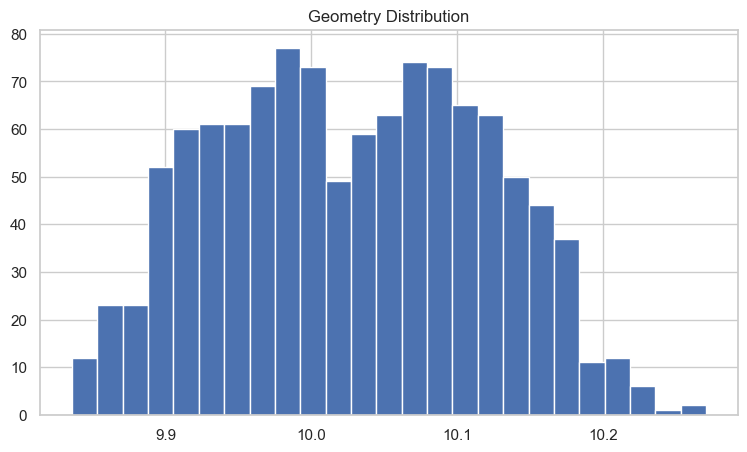

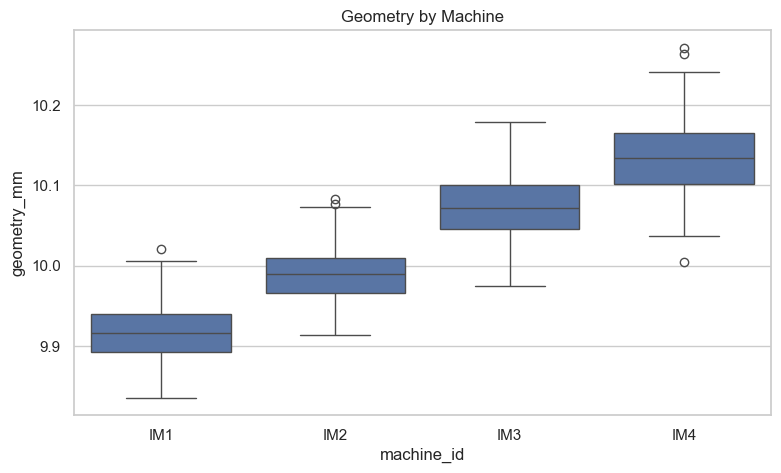

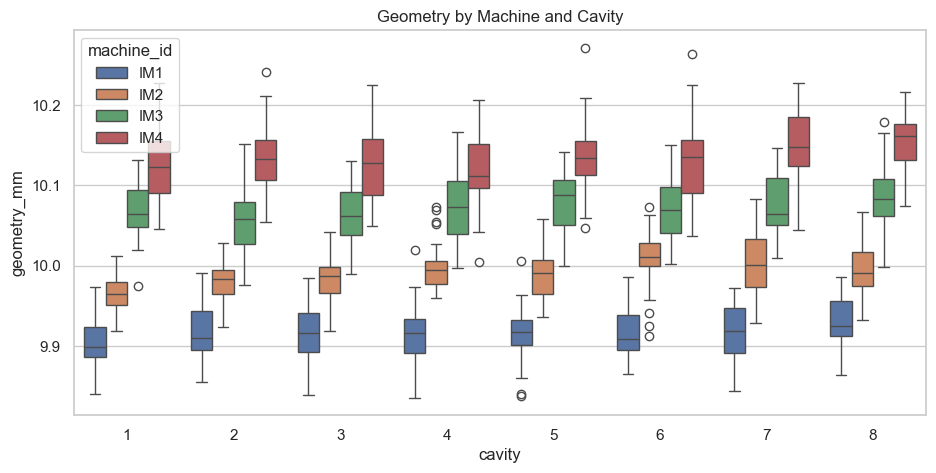

In [7]:
fig, ax = plt.subplots(figsize=(9,5))
ax.hist(lps["geometry_mm"], bins=25)
ax.set_title("Geometry Distribution"); plt.show()
fig, ax = plt.subplots(figsize=(9,5))
sns.boxplot(data=lps, x="machine_id", y="geometry_mm", ax=ax)
ax.set_title("Geometry by Machine"); plt.show()
fig, ax = plt.subplots(figsize=(11,5))
sns.boxplot(data=lps, x="cavity", y="geometry_mm", hue="machine_id", ax=ax)
ax.set_title("Geometry by Machine and Cavity"); plt.show()


The visual comparisons show clear geometry shifts across machines (mean geometry ranges from 9.9157 mm on IM1 to 10.1335 mm on IM4) and motivate drilling down by cavity and clipping result. 

Plots reveal patterns to test, but visual separation alone is not causal evidence.

## 8. Failure concentration

Use failure rate rather than only raw count. The machine × cavity grain is the key localization layer.

In [ ]:
failure_by_machine = lps.groupby("machine_id")["clip_ok"].agg(["count","mean"]).rename(columns={"count":"n","mean":"success_rate"})

failure_by_machine["failure_rate"] = 1-failure_by_machine.success_rate

display(failure_by_machine.sort_values("failure_rate", ascending=False))

display(machine_cavity[["machine_id","cavity","n","avg_geometry_mm","avg_clipping_gap_mm","clip_failure_rate"]].head(12))

,n,success_rate,failure_rate
machine_id,,,
IM4,280,0.832143,0.167857
IM1,280,0.985714,0.014286
IM3,280,0.989286,0.010714
IM2,280,1.000000,0.000000


,machine_id,cavity,n,avg_geometry_mm,avg_clipping_gap_mm,clip_failure_rate
0,IM4,7,35,10.147277,0.202563,0.314286
1,IM4,2,35,10.134717,0.195589,0.228571
2,IM4,8,35,10.154906,0.203823,0.200000
3,IM4,5,35,10.133826,0.190677,0.142857
4,IM4,6,35,10.129577,0.191789,0.142857
5,IM4,3,35,10.125737,0.186457,0.114286
6,IM4,4,35,10.120526,0.188263,0.114286
7,IM4,1,35,10.121354,0.184763,0.085714
8,IM1,1,35,9.902637,0.176894,0.057143
9,IM1,4,35,9.913843,0.164011,0.028571



Failures are concentrated in IM4: 47 of its 280 measurements fail clipping, compared with 0–4 failures on each other machine. 

IM4 cavity 7 has the largest observed rate (11 of 35, or 31.4%), so it is the strongest first candidate for a focused process and tool inspection.

## 9. Geometry and clipping result

Compare OK vs FAIL visually and inspect geometry vs gap. 

This builds the hypothesis but does not prove causality.

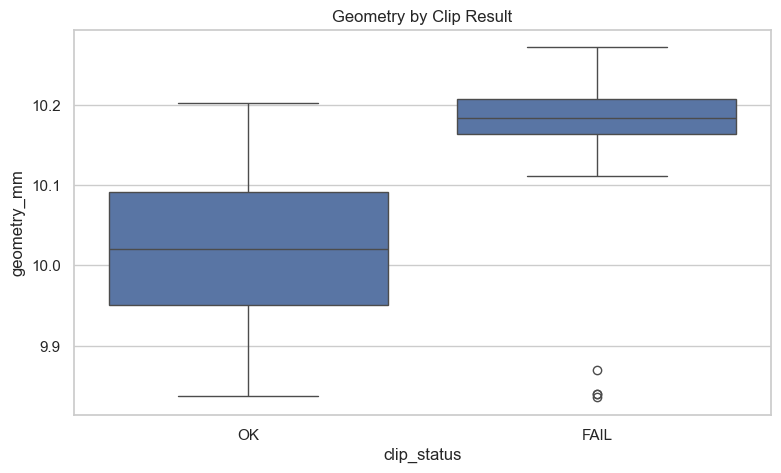

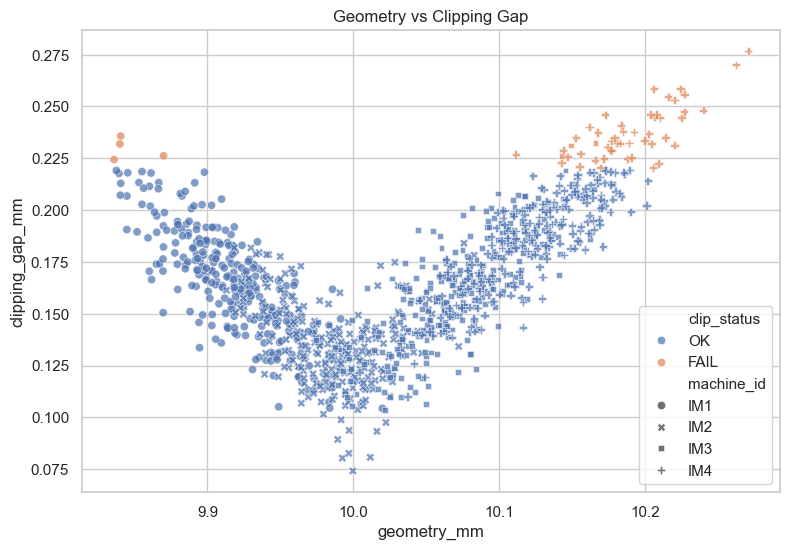

In [ ]:
fig, ax = plt.subplots(figsize=(9,5))
sns.boxplot(data=lps, x="clip_status", y="geometry_mm", ax=ax)
ax.set_title("Geometry by Clip Result"); 

plt.show()


fig, ax = plt.subplots(figsize=(9,6))
sns.scatterplot(data=lps, x="geometry_mm", y="clipping_gap_mm", hue="clip_status", style="machine_id", alpha=.7, ax=ax)
ax.set_title("Geometry vs Clipping Gap"); 

plt.show()


The FAIL group has higher mean geometry than the OK group (10.1639 mm vs 10.0206 mm); 

Welch's test (p=2.00e-15) and Mann–Whitney (p=3.40e-24) support a distributional difference. 

Treat this as evidence of association, not proof that geometry alone causes clipping failure.

## 10. Observation sequence

`measurement_id` is only an observation sequence unless true chronology is confirmed.

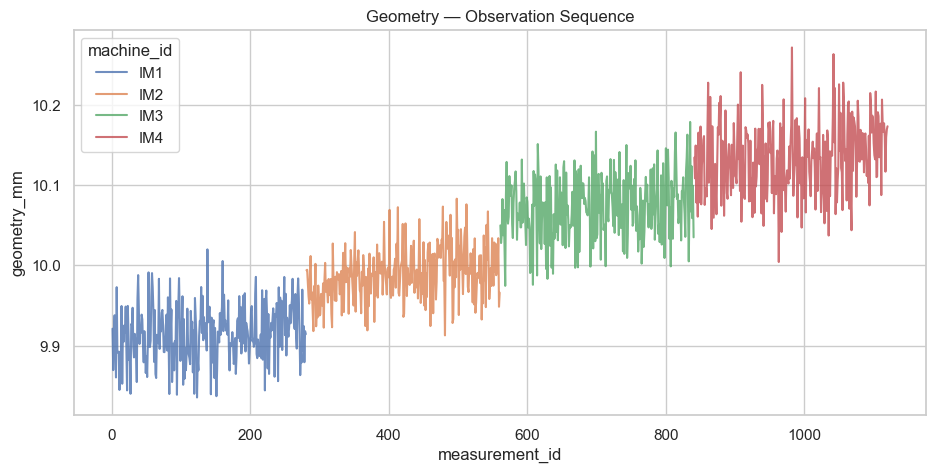

In [ ]:
fig, ax = plt.subplots(figsize=(11,5))
sns.lineplot(data=lps, x="measurement_id", y="geometry_mm", hue="machine_id", estimator=None, alpha=.8, ax=ax)
ax.set_title("Geometry — Observation Sequence"); 

plt.show()


`measurement_id` is grouped into consecutive machine blocks (IM1: 1–280, IM2: 281–560, IM3: 561–840, IM4: 841–1120), so the plot shows ordering by machine rather than verified process chronology. 

It cannot establish drift or a time trend; timestamps are needed before applying time-based SPC.

## 11. Statistical problem solving

### Normality diagnostics
Use Q-Q plot + histogram + Shapiro-Wilk as combined evidence.

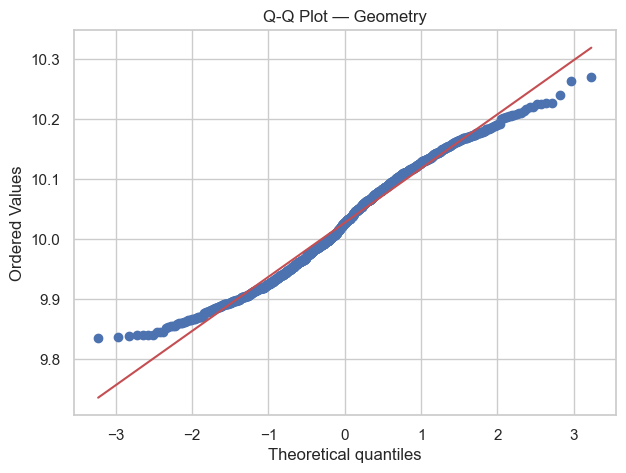

Shapiro-Wilk: statistic=0.9814, p=8.796e-11


In [ ]:
fig, ax = plt.subplots(figsize=(7,5))
stats.probplot(lps["geometry_mm"], dist="norm", plot=ax)
ax.set_title("Q-Q Plot — Geometry"); 

plt.show()

shapiro_stat, shapiro_p = stats.shapiro(lps["geometry_mm"])
print(f"Shapiro-Wilk: statistic={shapiro_stat:.4f}, p={shapiro_p:.4g}")

### Machine effect

Levene checks variance homogeneity; 

ANOVA evaluates whether at least one machine mean geometry differs. 

If variance equality is badly violated, Welch ANOVA is preferable in a production implementation.

In [12]:
machine_groups = [g["geometry_mm"].to_numpy() for _,g in lps.groupby("machine_id")]
levene = stats.levene(*machine_groups, center="median")
anova = stats.f_oneway(*machine_groups)
print("Levene:", levene)
print("ANOVA:", anova)

Levene: LeveneResult(statistic=11.600041585480593, pvalue=1.7258055612258081e-07)
ANOVA: F_onewayResult(statistic=1720.2910174613796, pvalue=0.0)


### Geometry of OK vs FAIL

Use Welch's t-test because group sizes and variances need not be equal. 

Mann-Whitney is added as a rank-based robustness check.

In [13]:
geometry_ok = lps.loc[lps.clip_ok==1,"geometry_mm"]
geometry_fail = lps.loc[lps.clip_ok==0,"geometry_mm"]
welch = stats.ttest_ind(geometry_ok, geometry_fail, equal_var=False)
mann = stats.mannwhitneyu(geometry_ok, geometry_fail, alternative="two-sided")
print("Welch:", welch)
print("Mann-Whitney:", mann)
print("Mean OK:", geometry_ok.mean(), "Mean FAIL:", geometry_fail.mean())

Welch: TtestResult(statistic=-10.790788431346689, pvalue=1.9982219415379482e-15, df=57.31643586866753)
Mann-Whitney: MannwhitneyuResult(statistic=5250.5, pvalue=3.404602810874713e-24)
Mean OK: 10.020603752345215 Mean FAIL: 10.16393888888889


### Geometry vs clipping gap

Pearson measures linear association; 

Spearman measures monotonic association. 

Neither proves a clipping mechanism.

In [14]:
pearson_r, pearson_p = stats.pearsonr(lps["geometry_mm"], lps["clipping_gap_mm"])
spearman_r, spearman_p = stats.spearmanr(lps["geometry_mm"], lps["clipping_gap_mm"])
print(f"Pearson r={pearson_r:.3f}, p={pearson_p:.4g}")
print(f"Spearman rho={spearman_r:.3f}, p={spearman_p:.4g}")

Pearson r=0.421, p=2.016e-49
Spearman rho=0.393, p=1.408e-42



The tests consistently indicate non-normal geometry (Shapiro p≈8.80e-11), unequal variance across machines (Levene p≈1.73e-07), and differences between machine means and OK/FAIL groups. 

Because equal-variance assumptions are not supported, give more weight to Welch and Mann–Whitney for the OK/FAIL comparison; all these results are observational and do not establish causality.

## 12. Status of the Analysis

In [15]:
python_stats = pd.DataFrame([
{"analysis":"Shapiro geometry_mm","statistic":shapiro_stat,"p_value":shapiro_p,"interpretation":"Normality diagnostic; use with Q-Q plot and histogram."},
{"analysis":"Levene geometry across machines","statistic":levene.statistic,"p_value":levene.pvalue,"interpretation":"Tests equality of geometry variance across machines."},
{"analysis":"One-way ANOVA geometry across machines","statistic":anova.statistic,"p_value":anova.pvalue,"interpretation":"Tests whether at least one machine mean differs."},
{"analysis":"Welch t-test geometry OK vs FAIL","statistic":welch.statistic,"p_value":welch.pvalue,"interpretation":"Compares mean geometry without equal-variance assumption."},
{"analysis":"Mann-Whitney geometry OK vs FAIL","statistic":mann.statistic,"p_value":mann.pvalue,"interpretation":"Rank-based robustness check."},
{"analysis":"Pearson geometry vs clipping_gap","statistic":pearson_r,"p_value":pearson_p,"interpretation":"Linear association; not causal evidence."},
{"analysis":"Spearman geometry vs clipping_gap","statistic":spearman_r,"p_value":spearman_p,"interpretation":"Monotonic association; not causal evidence."}
])
findings = pd.DataFrame([
{"topic":"Machine effect","finding":"Geometry and clipping performance differ between machines.","status":"Supported by current evidence"},
{"topic":"Cavity effect","finding":"Machine × cavity failure rates isolate subgroups hidden by machine averages.","status":"Inspect highest-risk cavities"},
{"topic":"Geometry and failures","finding":"OK and FAIL observations occupy different geometry distributions.","status":"Statistical association supported"},
{"topic":"Root cause","finding":"Observational data alone cannot separate geometry, clipping settings, mould condition and measurement-system effects causally.","status":"Requires controlled follow-up"}
])
with sqlite3.connect(DB_PATH) as con:
    python_stats.to_sql("gold_python_statistics", con, if_exists="replace", index=False)
    findings.to_sql("gold_problem_solving_findings", con, if_exists="replace", index=False)
display(python_stats); display(findings)

,analysis,statistic,p_value,interpretation
0,Shapiro geometry_mm,0.981410,8.796310e-11,Normality diagnostic; use with Q-Q plot and hi...
1,Levene geometry across machines,11.600042,1.725806e-07,Tests equality of geometry variance across mac...
2,One-way ANOVA geometry across machines,1720.291017,0.000000e+00,Tests whether at least one machine mean differs.
3,Welch t-test geometry OK vs FAIL,-10.790788,1.998222e-15,Compares mean geometry without equal-variance ...
4,Mann-Whitney geometry OK vs FAIL,5250.500000,3.404603e-24,Rank-based robustness check.
5,Pearson geometry vs clipping_gap,0.421338,2.016142e-49,Linear association; not causal evidence.
6,Spearman geometry vs clipping_gap,0.392575,1.407794e-42,Monotonic association; not causal evidence.


,topic,finding,status
0,Machine effect,Geometry and clipping performance differ betwe...,Supported by current evidence
1,Cavity effect,Machine × cavity failure rates isolate subgrou...,Inspect highest-risk cavities
2,Geometry and failures,OK and FAIL observations occupy different geom...,Statistical association supported
3,Root cause,Observational data alone cannot separate geome...,Requires controlled follow-up



The evidence supports prioritizing IM4 and its highest-failure cavities, and confirms dimensional differences between clipping OK/FAIL groups and an association with clipping gap. 

It does not isolate a single root cause: verify the measurement system, add timestamps and process settings, and use controlled trials before making a causal or production-capability claim.

## 13. Conclusion and next steps

### Conclusion
The dimensional process is not homogeneous across machines, failures are concentrated in specific subgroups, and OK/FAIL observations differ dimensionally.

These are strong diagnostic signals but not yet proof of a single causal root cause.

### Next steps
1. Inspect the highest-failure machine/cavity combinations physically.
2. Add timestamp, shift, material lot, mould temperature, injection pressure, cycle settings, maintenance and tool-change data.
3. Capture clipping-force / clipping-setting data.
4. Validate geometry and gap measurement systems with MSA / Gauge R&R.
5. Obtain approved LSL/USL before Cp/Cpk.
6. Use controlled trials or DOE to separate machine, cavity and clipping effects.
7. Introduce SPC only after chronological process data is available.

I treated the clipping symptom as an engineering problem instead of assuming the cause. 

I ingested the raw CSV to Bronze, created a validated Silver measurement table, and built Gold tables at machine, machine-cavity, clip-result and failed-measurement grains. 

I used visual drill-down first and statistics second. Python results were written back to SQLite so Streamlit could combine SQL KPIs with statistical evidence. 

I then separated what the current data supports from what needs controlled process validation.

## 14. Streamlit dashboard

The dashboard script is `lps_clipping_investigation_dashboard.py`. It combines the SQLite manufacturing tables with the leakage test CSV, and includes the real-vs-ideal capability comparison and clipping/leakage association analysis.

Start it from this project directory with:

`streamlit run lps_clipping_investigation_dashboard.py`

## 15. Add a second source — Leakage test results

New flow:

`lps_geometry.csv + lps_leakage_results.csv → separate Bronze tables → validated Silver tables → one-to-one join on measurement_id → Gold analytics`

The leakage source is intentionally kept independent until the join. Before analysis, validate that `measurement_id` is unique in both sources so the join does not multiply rows.

For this portfolio/training project, `lps_leakage_results.csv` is synthetic. Replace it with a real test export for production use.


In [7]:
leakage = pd.read_csv("lps_leakage_results.csv")

assert lps["measurement_id"].is_unique
assert leakage["measurement_id"].is_unique

lps_joined = lps.merge(
    leakage,
    on="measurement_id",
    how="left",
    validate="one_to_one"
)

print("Rows before join:", len(lps))
print("Rows after join :", len(lps_joined))
print("Unmatched:", lps_joined["leakage_test_id"].isna().sum())
display(lps_joined.head())


Rows before join: 1120
Rows after join : 1120
Unmatched: 0


,measurement_id,machine_id,cavity,geometry_mm,clipping_gap_mm,clip_ok,clip_status,leakage_test_id,leakage_value,leakage_limit,leakage_ok,leakage_status
0,1,IM1,1,9.9214,0.1553,1,OK,1,0.2687,0.34,1,OK
1,2,IM1,1,9.8699,0.2262,0,FAIL,2,0.2694,0.34,1,OK
2,3,IM1,1,9.9174,0.1544,1,OK,3,0.3092,0.34,1,OK
3,4,IM1,1,9.9381,0.1524,1,OK,4,0.2995,0.34,1,OK
4,5,IM1,1,9.8971,0.1850,1,OK,5,0.1274,0.34,1,OK


## 16. Statistical question — Clipping OK/FAIL vs Leakage OK/FAIL

This section checks whether the two test outcomes are statistically associated. 

The null hypothesis 
* (H₀) says that clipping and leakage results are independent; 
* the alternative (H₁) says that the observed outcomes are associated. 

The chi-square test compares the observed counts in the contingency table with the counts expected under independence. 

Fisher's exact test provides an exact check for a 2×2 table, especially useful when expected cell counts are small.



In [9]:
contingency = pd.crosstab(lps_joined["clip_status"], lps_joined["leakage_status"])
display(contingency)

chi2, chi_p, dof, expected = stats.chi2_contingency(contingency)
phi = np.sqrt(chi2 / contingency.to_numpy().sum())

a = ((lps_joined.clip_status=="FAIL") & (lps_joined.leakage_status=="FAIL")).sum()
b = ((lps_joined.clip_status=="FAIL") & (lps_joined.leakage_status=="OK")).sum()
c = ((lps_joined.clip_status=="OK") & (lps_joined.leakage_status=="FAIL")).sum()
d = ((lps_joined.clip_status=="OK") & (lps_joined.leakage_status=="OK")).sum()

odds_ratio, fisher_p = stats.fisher_exact([[a,b],[c,d]])

print(f"Chi-square={chi2:.4f}, p={chi_p:.6g}, Phi={phi:.3f}")
print(f"Odds ratio={odds_ratio:.3f}, Fisher p={fisher_p:.6g}")


leakage_status,FAIL,OK
clip_status,,
FAIL,44,10
OK,164,902


Chi-square=144.1430, p=3.30625e-33, Phi=0.359
Odds ratio=24.200, Fisher p=5.58152e-25


* The current results are **χ²=144.143, p=3.31e-33, φ=0.359**, with an **odds ratio of 24.20** and Fisher **p<0.001**. 

* The very small p-values are strong evidence against independence in this dataset; they do not mean the null hypothesis has a 3.31e-33 probability of being true. 

* Phi summarizes association strength (0 means no association; 1 means perfect association for a 2×2 table), so 0.359 indicates a meaningful, non-perfect relationship. 

* The odds ratio means the observed odds of a leakage failure are about 24 times higher among measurements marked clipping FAIL than among measurements marked clipping OK. It is not a 24-fold increase in failure probability.

These results prioritize measurements with clipping failures for investigation, but they do not establish that clipping failure causes leakage failure. 

Shared process conditions, machine or cavity differences, and measurement effects may influence both outcomes. 

Confirm the pattern by inspecting subgroup rates and confidence intervals, validating the tests and measurement systems, and checking it against additional production data before changing the process.

## 17. Geometry vs Leakage result

Use:
- boxplot / histogram first;
- Welch t-test for mean comparison without assuming equal variances;
- Mann–Whitney as a rank-based robustness check;
- Pearson and Spearman for geometry vs the continuous leakage measurement.


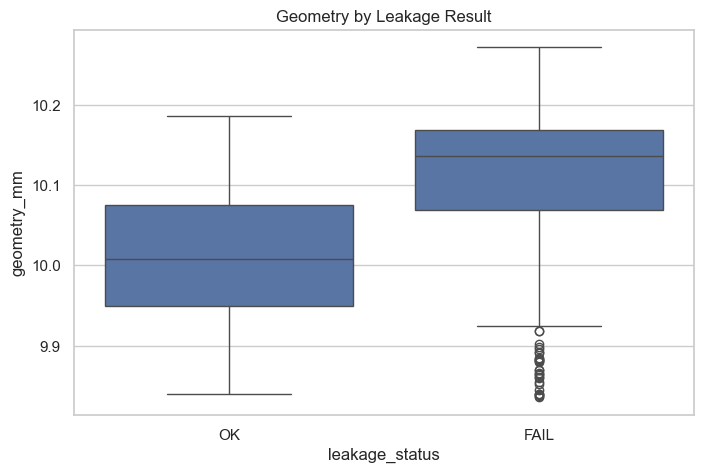

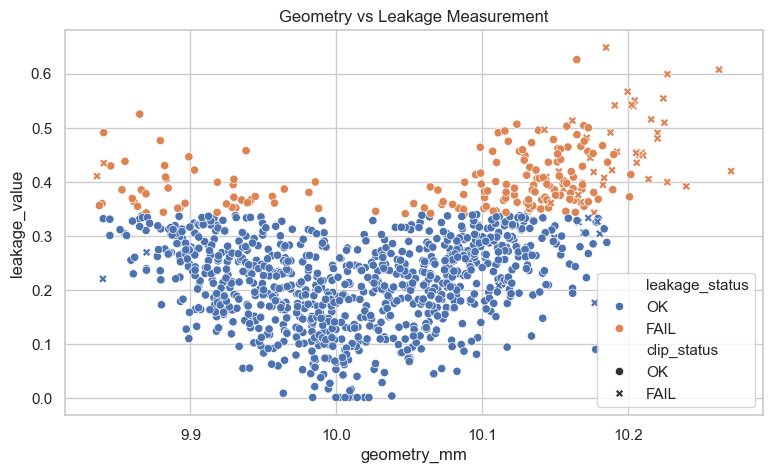

TtestResult(statistic=-10.111589877257645, pvalue=2.0105584495404137e-20, df=254.40649835606249)
MannwhitneyuResult(statistic=46166.5, pvalue=6.251682515286542e-31)
PearsonRResult(statistic=0.33007292290381174, pvalue=7.106643104985767e-30)
SignificanceResult(statistic=0.29517416393625556, pvalue=5.925906807762463e-24)


In [19]:
fig, ax = plt.subplots(figsize=(8,5))
sns.boxplot(data=lps_joined, x="leakage_status", y="geometry_mm", ax=ax)
ax.set_title("Geometry by Leakage Result")
plt.show()

fig, ax = plt.subplots(figsize=(9,5))
sns.scatterplot(
    data=lps_joined,
    x="geometry_mm",
    y="leakage_value",
    hue="leakage_status",
    style="clip_status",
    ax=ax
)
ax.set_title("Geometry vs Leakage Measurement")
plt.show()

geometry_leak_ok = lps_joined.loc[lps_joined.leakage_status=="OK","geometry_mm"]
geometry_leak_fail = lps_joined.loc[lps_joined.leakage_status=="FAIL","geometry_mm"]

print(stats.ttest_ind(geometry_leak_ok, geometry_leak_fail, equal_var=False))
print(stats.mannwhitneyu(geometry_leak_ok, geometry_leak_fail, alternative="two-sided"))
print(stats.pearsonr(lps_joined["geometry_mm"], lps_joined["leakage_value"]))
print(stats.spearmanr(lps_joined["geometry_mm"], lps_joined["leakage_value"]))


## 18. Process capability — Cp and Cpk

For geometry:

`Cp = (USL - LSL) / (6σ)`

`Cpk = min[(USL - μ)/(3σ), (μ - LSL)/(3σ)]`

Also calculate:

`mean deviation from target = μ - target`

Interpretation:
- Cp measures potential capability from spread.
- Cpk adds the effect of centering.
- Cp > Cpk means centering is reducing capability.
- Cp and Cpk below 1 indicate that the estimated process spread and/or centering do not fit within the specification limits.
- Capability must only be treated as a production statement after stability and MSA are demonstrated.

The values below use **training limits** LSL=9.80 mm and USL=10.20 mm. Replace them with approved engineering specifications.

For a visual benchmark, the comparison uses an **ideal normal distribution centered on the target with Cp=Cpk=1.33**. Its standard deviation is calculated as `(USL - LSL) / (6 × 1.33)`, giving about **0.0501 mm** for these limits. The real observations are shown as a density histogram with a KDE; the ideal is a theoretical normal curve, not simulated or measured data. A capability target of 1.33 is a common illustrative benchmark, not a universal customer or regulatory requirement.

,Real process,Ideal benchmark (Cp=Cpk=1.33)
n,1120.000000,NaN
mean,10.027515,10.000000
sigma,0.090867,0.050125
target,10.000000,10.000000
deviation_from_target,0.027515,0.000000
Cp,0.733672,1.330000
Cpk,0.632739,1.330000


,n,mean,sigma,target,deviation_from_target,Cp,Cpk
machine_id,,,,,,,
IM1,280.0,9.915687,0.035216,10.0,-0.084313,1.893054,1.095007
IM2,280.0,9.989346,0.032844,10.0,-0.010654,2.029811,1.921680
IM3,280.0,10.071536,0.039366,10.0,0.071536,1.693504,1.087774
IM4,280.0,10.133490,0.044937,10.0,0.133490,1.483574,0.493363


n       mean     sigma  target  deviation_from_target  \
machine_id cavity                                                             
IM4        7       35.0  10.147277  0.045390    10.0               0.147277   
           8       35.0  10.154906  0.035717    10.0               0.154906   
           6       35.0  10.129577  0.052608    10.0               0.129577   
           2       35.0  10.134717  0.043545    10.0               0.134717   
           5       35.0  10.133826  0.043373    10.0               0.133826   
           3       35.0  10.125737  0.042522    10.0               0.125737   
           1       35.0  10.121354  0.043810    10.0               0.121354   
           4       35.0  10.120526  0.043475    10.0               0.120526   
IM3        8       35.0  10.085380  0.042100    10.0               0.085380   
           4       35.0  10.072323  0.044128    10.0               0.072323   
IM1        3       35.0   9.913269  0.038086    10.0              -0.086731   
           2       35.0   9.917629  0.039056    10.0              -0.082371   
           4       35.0   9.913843  0.037012    10.0              -0.086157   
           1       35.0   9.902637  0.032800    10.0              -0.097363   
IM3        2       35.0  10.057051  0.043654    10.0               0.057051   
IM1        5       35.0   9.913863  0.034499    10.0              -0.086137   
IM3        7       35.0  10.076349  0.037382    10.0               0.076349   
IM1        7       35.0   9.918306  0.035457    10.0              -0.081694   
IM3        5       35.0  10.079694  0.034923    10.0               0.079694   
           6       35.0  10.068054  0.037570    10.0               0.068054   
           3       35.0  10.064174  0.036776    10.0               0.064174   
           1       35.0  10.069260  0.033621    10.0               0.069260   
IM1        6       35.0   9.916583  0.029932    10.0              -0.083417   
           8       35.0   9.929366  0.031927    10.0              -0.070634   
IM2        7       35.0  10.000977  0.039079    10.0               0.000977   
           6       35.0  10.008194  0.034500    10.0               0.008194   
           8       35.0   9.994177  0.031626    10.0              -0.005823   
           5       35.0   9.988189  0.030009    10.0              -0.011811   
           3       35.0   9.981726  0.028686    10.0              -0.018274   
           4       35.0   9.996806  0.029138    10.0              -0.003194   
           2       35.0   9.980069  0.025652    10.0              -0.019931   
           1       35.0   9.964629  0.023213    10.0              -0.035371   

                         Cp       Cpk  
machine_id cavity                      
IM4        7       1.468752  0.387184  
           8       1.866532  0.420850  
           6       1.267243  0.446214  
           2       1.530992  0.499738  
           5       1.537057  0.508568  
           3       1.567814  0.582152  
           1       1.521723  0.598385  
           4       1.533462  0.609354  
IM3        8       1.583516  0.907513  
           4       1.510763  0.964450  
IM1        3       1.750413  0.991334  
           2       1.706964  1.003938  
           4       1.801220  1.025280  
           1       2.032506  1.043053  
IM3        2       1.527144  1.091515  
IM1        5       1.932439  1.100165  
IM3        7       1.783397  1.102598  
IM1        7       1.880213  1.112200  
IM3        5       1.908974  1.148302  
           6       1.774487  1.170680  
           3       1.812780  1.231110  
           1       1.982898  1.296220  
IM1        6       2.227267  1.298306  
           8       2.088067  1.350621  
IM2        7       1.705960  1.697625  
           6       1.932371  1.853199  
           8       2.107968  2.046596  
           5       2.221584  2.090383  
           3       2.324024  2.111675  
           4       2.287994  2.251452  
           2       2.598924  2.339922  
           1   

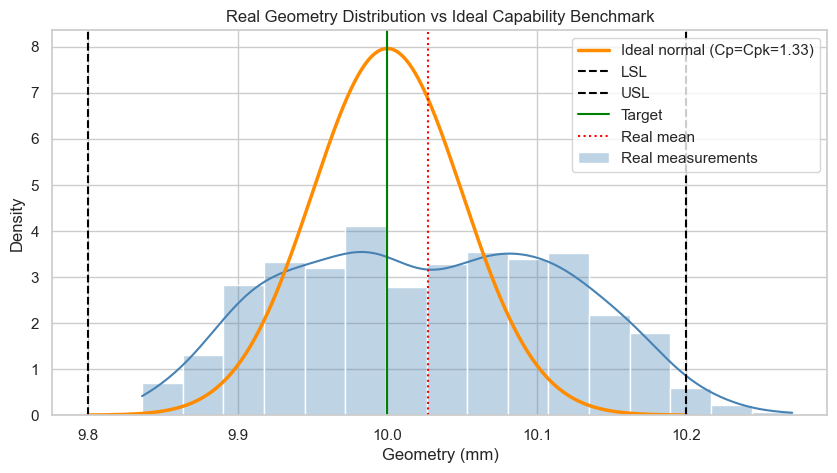

In [8]:
LSL = 9.80
USL = 10.20
TARGET = (LSL + USL)/2
IDEAL_CAPABILITY = 1.33
IDEAL_SIGMA = (USL - LSL) / (6 * IDEAL_CAPABILITY)


def capability(x, lsl=LSL, usl=USL):
    x = pd.Series(x).dropna()
    mu = x.mean()
    sigma = x.std(ddof=1)
    cp = (usl-lsl)/(6*sigma)
    cpk = min((usl-mu)/(3*sigma), (mu-lsl)/(3*sigma))
    return pd.Series({
        "n": len(x),
        "mean": mu,
        "sigma": sigma,
        "target": (lsl+usl)/2,
        "deviation_from_target": mu-(lsl+usl)/2,
        "Cp": cp,
        "Cpk": cpk
    })

real_overall = capability(lps_joined["geometry_mm"])
ideal_overall = pd.Series({
    "n": np.nan,
    "mean": TARGET,
    "sigma": IDEAL_SIGMA,
    "target": TARGET,
    "deviation_from_target": 0.0,
    "Cp": IDEAL_CAPABILITY,
    "Cpk": IDEAL_CAPABILITY
})
display(pd.DataFrame({
    "Real process": real_overall,
    "Ideal benchmark (Cp=Cpk=1.33)": ideal_overall
}))

display(
    lps_joined.groupby("machine_id")["geometry_mm"]
    .apply(capability).unstack()
)

display(
    lps_joined.groupby(["machine_id","cavity"])["geometry_mm"]
    .apply(capability).unstack()
    .sort_values("Cpk")
)

fig, ax = plt.subplots(figsize=(10,5))
sns.histplot(
    lps_joined["geometry_mm"],
    stat="density",
    bins="auto",
    kde=True,
    color="steelblue",
    alpha=0.35,
    label="Real measurements",
    ax=ax
)
ideal_x = np.linspace(TARGET - 4*IDEAL_SIGMA, TARGET + 4*IDEAL_SIGMA, 400)
ax.plot(
    ideal_x,
    stats.norm.pdf(ideal_x, loc=TARGET, scale=IDEAL_SIGMA),
    color="darkorange",
    linewidth=2.5,
    label="Ideal normal (Cp=Cpk=1.33)"
)
ax.axvline(LSL, color="black", linestyle="--", label="LSL")
ax.axvline(USL, color="black", linestyle="--", label="USL")
ax.axvline(TARGET, color="green", linestyle="-", label="Target")
ax.axvline(lps_joined["geometry_mm"].mean(), color="red", linestyle=":", label="Real mean")
ax.legend()
ax.set_title("Real Geometry Distribution vs Ideal Capability Benchmark")
ax.set_xlabel("Geometry (mm)")
ax.set_ylabel("Density")
plt.show()

## 19. Conclusion

The analysis identifies a **clear relationship between dimensional behavior, clipping performance, and leakage failures**, providing a strong basis for a focused root-cause investigation.

The most relevant signal is clipping performance. Parts classified as **clipping FAIL show approximately 24 times higher odds of leakage failure** compared with parts classified as clipping OK. This makes clipping one of the main areas to prioritize in the investigation.

At the same time, dimensional behavior is also associated with leakage. Leakage failures occur under significantly different geometry conditions, and higher geometry values tend to be associated with higher leakage measurements. This suggests that **clipping and geometry should be investigated as interacting process signals rather than independently**.

The process capability assessment also indicates a structural process issue. With the current dataset specification limits, **Cp=0.734 and Cpk=0.633**, showing that the process variation is wider than the available tolerance range. The process is additionally shifted toward and upper specification limit (as show in the histogram).

Therefore, **re-centering alone will not be sufficient**. The main improvement opportunity is first to reduce process variation and then optimize process centering.

### Next steps

The next investigation should determine whether the observed failures are:
* concentrated in specific machines or cavities;
* associated with particular dimensional ranges;
* linked to clipping performance;

